Generating Churn Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

RNG = 42
rng = np.random.default_rng(RNG)
N = 4000

# Latent signal: 5 informative directions separating churners from stayers.
X_num, y = make_classification(
    n_samples=N, n_features=6, n_informative=5, n_redundant=0,
    n_clusters_per_class=1, weights=[0.76, 0.24], flip_y=0.13,
    class_sep=0.85, random_state=RNG)
Xs = (X_num - X_num.mean(0)) / X_num.std(0)   # standardise before rescaling so signal survives

df = pd.DataFrame()
# --- numeric account features (rescaled to human-readable ranges) ---
df["tenure_months"]    = np.clip(Xs[:, 4] * 12 + 34, 1, 72).round().astype(int)
df["monthly_charges"]  = np.clip(Xs[:, 0] * 13 + 72, 18, 130).round(2)
df["support_tickets"]  = np.clip(Xs[:, 2] * 1.7 + 3, 0, 25).round().astype(int)
df["avg_latency_ms"]   = np.clip(Xs[:, 3] * 35 + 120, 20, 400).round().astype(int)
df["addons_count"]     = np.clip(Xs[:, 1] * 1.3 + 4, 0, 8).round().astype(int)
df["days_since_login"] = np.clip(-Xs[:, 4] * 8 + 16 + rng.normal(0, 4, N), 0, 90).round().astype(int)
df["total_charges"]    = (df["monthly_charges"] * df["tenure_months"]).round(2)

# --- categorical plan features, correlated with churn like the real world ---
def by_class(p_churn, p_stay, choices):
    out = np.empty(N, dtype=object); m = (y == 1)
    out[m]  = rng.choice(choices, m.sum(),  p=p_churn)
    out[~m] = rng.choice(choices, (~m).sum(), p=p_stay)
    return out

df["contract_type"]    = by_class([0.75,0.18,0.07],[0.34,0.35,0.31],
                                   ["Month-to-month","One year","Two year"])
df["payment_method"]   = by_class([0.55,0.20,0.15,0.10],[0.25,0.30,0.25,0.20],
                                   ["Electronic check","Mailed check","Bank transfer","Credit card"])
df["internet_service"] = by_class([0.65,0.28,0.07],[0.40,0.35,0.25],
                                   ["Fiber optic","DSL","None"])
df["has_dependents"]   = by_class([0.82,0.18],[0.60,0.40], ["No","Yes"])

# --- the TRAP: a post-outcome flag that leaks the label (you'll remove it in Step 2) ---
df["exit_survey_sent"] = np.where(y == 1, rng.binomial(1,0.97,N), rng.binomial(1,0.02,N))

df["churn"] = y
print("dataset shape:", df.shape)
print("churn rate:   ", round(df["churn"].mean(), 3))
df.head()

dataset shape: (4000, 13)
churn rate:    0.275


,tenure_months,monthly_charges,support_tickets,avg_latency_ms,addons_count,days_since_login,total_charges,contract_type,payment_method,internet_service,has_dependents,exit_survey_sent,churn
0,39,75.42,2,93,3,14,2941.38,Two year,Electronic check,DSL,Yes,0,0
1,47,66.68,2,149,1,3,3133.96,One year,Bank transfer,None,No,0,0
2,40,55.45,4,87,4,15,2218.00,One year,Electronic check,None,No,0,0
3,28,74.94,4,192,7,24,2098.32,Month-to-month,Electronic check,Fiber optic,Yes,1,1
4,56,55.73,3,69,2,0,3120.88,Two year,Mailed check,Fiber optic,No,0,0


EDA

churn
0    0.725
1    0.275
Name: proportion, dtype: float64 

churn                  0       1
tenure_months       37.4    25.0
monthly_charges     72.2    71.5
support_tickets      2.5     4.3
avg_latency_ms     120.1   119.8
addons_count         4.0     4.0
days_since_login    13.7    22.0
total_charges     2605.0  1710.3 

contract_type
Month-to-month    0.463
One year          0.159
Two year          0.059
Name: churn, dtype: float64


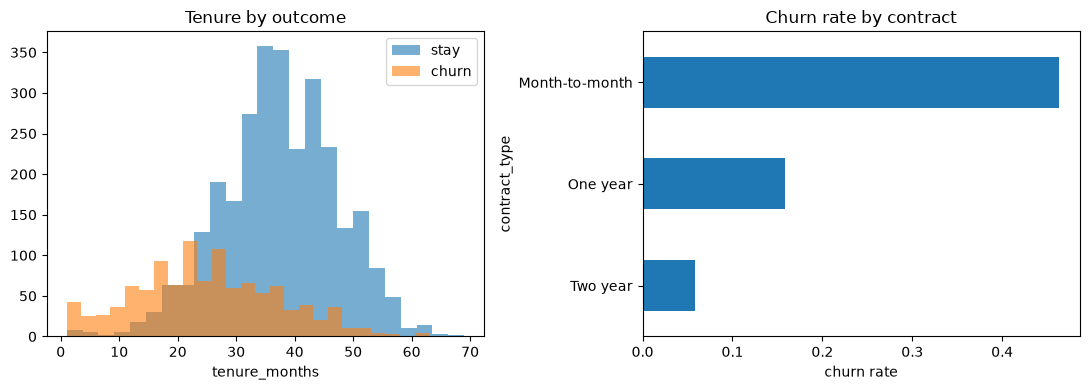

In [2]:
# Class balance
print(df["churn"].value_counts(normalize=True).round(3), "\n")

# How do the numeric drivers differ between churners and stayers?
num_cols = ["tenure_months","monthly_charges","support_tickets",
            "avg_latency_ms","addons_count","days_since_login","total_charges"]
print(df.groupby("churn")[num_cols].mean().round(1).T, "\n")

# Churn rate by contract type — a categorical driver
print(df.groupby("contract_type")["churn"].mean().round(3).sort_values(ascending=False))

# Visualise tenure vs churn
fig, ax = plt.subplots(1, 2, figsize=(11,4))
for k, lbl in [(0,"stay"),(1,"churn")]:
    ax[0].hist(df.loc[df.churn==k,"tenure_months"], bins=25, alpha=0.6, label=lbl)
ax[0].set_title("Tenure by outcome"); ax[0].set_xlabel("tenure_months"); ax[0].legend()
df.groupby("contract_type")["churn"].mean().sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Churn rate by contract"); ax[1].set_xlabel("churn rate")
plt.tight_layout(); plt.show()

In [3]:
from sklearn.model_selection import train_test_split

# Leakage check #1 — a feature that "knows" the answer
leak_scores = df.corr(numeric_only=True)["churn"].drop("churn").abs().sort_values(ascending=False)
print("abs. correlation with churn:\n", leak_scores.round(3), "\n")
suspects = leak_scores[leak_scores > 0.9].index.tolist()
print("LEAK suspects (corr > 0.9):", suspects)

df_clean = df.drop(columns=suspects)          # drop exit_survey_sent
X = df_clean.drop(columns=["churn"])
y = df_clean["churn"]

# 70% train / 15% validation / 15% test, stratified to keep the churn rate stable
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RNG)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RNG)

print("\nshapes:", X_train.shape, X_val.shape, X_test.shape)
print("churn rate  train/val/test:",
      round(y_train.mean(),3), round(y_val.mean(),3), round(y_test.mean(),3))

abs. correlation with churn:
 exit_survey_sent    0.947
total_charges       0.566
tenure_months       0.465
support_tickets     0.454
days_since_login    0.419
monthly_charges     0.022
addons_count        0.019
avg_latency_ms      0.004
Name: churn, dtype: float64 

LEAK suspects (corr > 0.9): ['exit_survey_sent']

shapes: (2800, 11) (600, 11) (600, 11)
churn rate  train/val/test: 0.275 0.275 0.275


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = X_train.select_dtypes("number").columns.tolist()
cat_features = X_train.select_dtypes("object").columns.tolist()
print("numeric :", num_features)
print("categorical:", cat_features)

pre = ColumnTransformer([
    ("num", StandardScaler(),                          num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),    cat_features),
])

# Sanity-check the transform width (fit on TRAIN ONLY)
Z = pre.fit_transform(X_train)
print("\ntransformed matrix:", Z.shape)
print("feature count after one-hot:", len(pre.get_feature_names_out()))

numeric : ['tenure_months', 'monthly_charges', 'support_tickets', 'avg_latency_ms', 'addons_count', 'days_since_login', 'total_charges']
categorical: ['contract_type', 'payment_method', 'internet_service', 'has_dependents']

transformed matrix: (2800, 19)
feature count after one-hot: 19


In [5]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    "LogReg":       LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=RNG,
                                           class_weight="balanced"),
    "GradBoost":    GradientBoostingClassifier(random_state=RNG),
    "SVM_RBF":      SVC(kernel="rbf", probability=True, class_weight="balanced",
                        random_state=RNG),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
results = {}
for name, clf in models.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    results[name] = scores
    print(f"{name:13s} ROC-AUC = {scores.mean():.3f} +/- {scores.std():.3f}")

LogReg        ROC-AUC = 0.938 +/- 0.015
RandomForest  ROC-AUC = 0.936 +/- 0.019
GradBoost     ROC-AUC = 0.940 +/- 0.013
SVM_RBF       ROC-AUC = 0.941 +/- 0.012


In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

gb_pipe = Pipeline([("pre", pre),
                    ("clf", GradientBoostingClassifier(random_state=RNG))])

param_grid = {
    "clf__n_estimators":  [150, 300],
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_depth":     [2, 3],
}

grid = GridSearchCV(gb_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("best params:", grid.best_params_)
print("best CV ROC-AUC:", round(grid.best_score_, 3))

best_model = grid.best_estimator_
val_auc = roc_auc_score(y_val, best_model.predict_proba(X_val)[:, 1])
print("validation ROC-AUC:", round(val_auc, 3))

best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 150}
best CV ROC-AUC: 0.941
validation ROC-AUC: 0.94


TEST ROC-AUC: 0.951 

              precision    recall  f1-score   support

        stay      0.916     0.954     0.935       435
       churn      0.864     0.770     0.814       165

    accuracy                          0.903       600
   macro avg      0.890     0.862     0.874       600
weighted avg      0.902     0.903     0.902       600



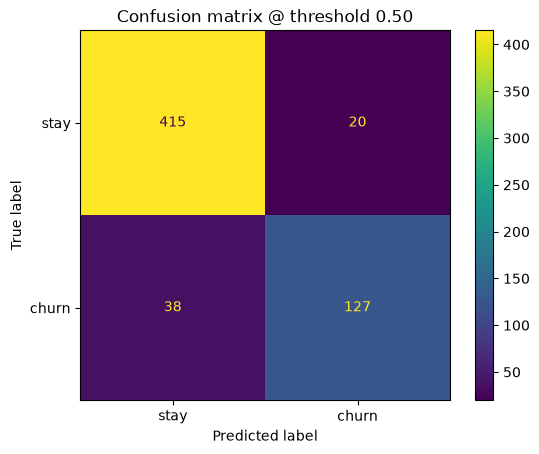

  thr  precision   recall     f1
 0.50      0.864    0.770  0.814
 0.40      0.805    0.800  0.802
 0.35      0.780    0.836  0.807
 0.30      0.728    0.842  0.781
 0.25      0.703    0.861  0.774


In [7]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             precision_score, recall_score, f1_score)

proba = best_model.predict_proba(X_test)[:, 1]
pred_050 = (proba >= 0.50).astype(int)

print("TEST ROC-AUC:", round(roc_auc_score(y_test, proba), 3), "\n")
print(classification_report(y_test, pred_050, target_names=["stay","churn"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_050),
                       display_labels=["stay","churn"]).plot(values_format="d")
plt.title("Confusion matrix @ threshold 0.50"); plt.show()

# Business trade-off: sweep the decision threshold
print(f"{'thr':>5} {'precision':>10} {'recall':>8} {'f1':>6}")
for t in [0.50, 0.40, 0.35, 0.30, 0.25]:
    p = (proba >= t).astype(int)
    print(f"{t:5.2f} {precision_score(y_test,p):10.3f} "
          f"{recall_score(y_test,p):8.3f} {f1_score(y_test,p):6.3f}")

Permutation importance (ROC-AUC drop when shuffled):
total_charges       0.1045
contract_type       0.0525
support_tickets     0.0370
internet_service    0.0186
payment_method      0.0179
monthly_charges     0.0094
has_dependents      0.0082
tenure_months       0.0027
addons_count        0.0014
days_since_login    0.0013
avg_latency_ms     -0.0004
dtype: float64 

Most churn-DRIVING (positive coef):
 cat__internet_service_Fiber optic       0.72
num__support_tickets                    0.92
cat__payment_method_Electronic check    0.94
cat__contract_type_Month-to-month       1.28
dtype: float64 

Most PROTECTIVE (negative coef):
 num__tenure_months            -1.75
num__monthly_charges          -1.34
cat__contract_type_Two year   -1.14
cat__internet_service_None    -0.81
dtype: float64


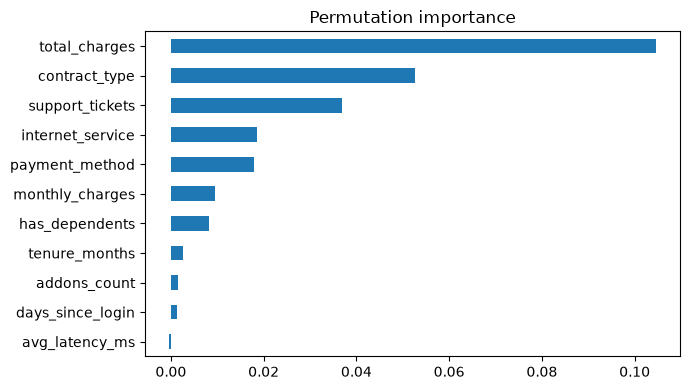

In [8]:
from sklearn.inspection import permutation_importance

# 1) Permutation importance of the tuned GradientBoosting model (on validation)
perm = permutation_importance(best_model, X_val, y_val,
                              n_repeats=8, random_state=RNG, scoring="roc_auc")
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print("Permutation importance (ROC-AUC drop when shuffled):")
print(imp.round(4), "\n")

# 2) Signed drivers from an interpretable LogReg baseline
logreg = Pipeline([("pre", pre),
                   ("clf", LogisticRegression(max_iter=2000,
                                              class_weight="balanced"))]).fit(X_train, y_train)
coef = pd.Series(logreg.named_steps["clf"].coef_[0],
                 index=logreg.named_steps["pre"].get_feature_names_out())
print("Most churn-DRIVING (positive coef):\n", coef.sort_values().tail(4).round(2), "\n")
print("Most PROTECTIVE (negative coef):\n", coef.sort_values().head(4).round(2))

imp.sort_values().plot.barh(figsize=(7,4), title="Permutation importance"); plt.tight_layout(); plt.show()

In [9]:
summary = {
    "primary_metric": "recall on churn (ROC-AUC for selection)",
    "chosen_model": "GradientBoosting (tuned)",
    "test_roc_auc": round(roc_auc_score(y_test, proba), 3),
    "operating_threshold": 0.30,
}
p30 = (proba >= 0.30).astype(int)
summary["recall_at_0.30"]    = round(recall_score(y_test, p30), 3)
summary["precision_at_0.30"] = round(precision_score(y_test, p30), 3)
summary["top_drivers"]       = imp.head(3).index.tolist()
for k, v in summary.items():
    print(f"{k:22s}: {v}")

primary_metric        : recall on churn (ROC-AUC for selection)
chosen_model          : GradientBoosting (tuned)
test_roc_auc          : 0.951
operating_threshold   : 0.3
recall_at_0.30        : 0.842
precision_at_0.30     : 0.728
top_drivers           : ['total_charges', 'contract_type', 'support_tickets']
